# Informe del modelo de riesgo · Saber 11 en el Valle del Cauca
**Modelo de clasificación «estudiante en riesgo» versión 2.0**

Proyecto ETL, entrega final. Este informe documenta el modelo que usa el consumidor de Kafka y el dashboard en tiempo real.
Se genera **directamente desde el Data Warehouse** (`saber11_dw_e2`) y desde los artefactos de `models/`: el modelo se
**carga ya entrenado** y se evalúa sobre el 20 % de prueba que quedó guardado en `models/ids_test.csv`.
Las cifras del texto se calculan al ejecutar el notebook.

**Resumen.** Dado el perfil socioeconómico de un estudiante, su colegio y su municipio, el modelo estima qué tan probable
es que quede en el 25 % más bajo de puntaje global de su semestre. Sirve para **priorizar dónde enfocar apoyo**, no para decidir sobre una persona.

In [1]:
import json, os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             roc_curve, confusion_matrix)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELOS = RAIZ / "models"
sys.path.insert(0, str(RAIZ / "ml"))
import entrenar_modelo as base          


def num(x, dec=1):
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def pct(x, dec=1):
    return num(100 * x, dec) + " %"

azul, naranja, gris = "#0D4EB7", "#e08a1e", "#8a8f98"

## 1. El problema y cómo se define «riesgo»
- **Objetivo:** identificar estudiantes con alta probabilidad de quedar en el **25 % más bajo** del puntaje global de su semestre.
- **Etiqueta:** `riesgo = 1` si `punt_global` es menor o igual al percentil 25 **de su semestre**. Los umbrales se calculan **solo con los datos de entrenamiento**.
  Se hace por semestre porque los dos semestres no son comparables entre sí, ya que el calendario de los colegios y el tipo de examinados cambian.
- **Entradas usamos 11 variables, sin puntajes:** semestre, estrato, educación del padre y de la madre, internet, computador, personas en el hogar,
  naturaleza, calendario y zona del colegio, y municipio. A estas se suma **una variable calculada: el historial de riesgo del colegio**.
- **Salidas:** probabilidad de riesgo (`probability_riesgo`) y etiqueta `en_riesgo` / `sin_riesgo`.

**Qué no entra al modelo:** ningún puntaje global ni por área, porque serían la misma respuesta *fuga de datos*.

In [2]:
base.cargar_env(RAIZ / ".env")
artefacto = joblib.load(MODELOS / "modelo_riesgo.joblib")
modelo, meta = artefacto["model"], artefacto["metadata"]
met = json.loads((MODELOS / "metricas.json").read_text(encoding="utf-8"))

COL_HIST = meta["columna_historial"]
UMBRAL = float(meta["decision_threshold"])
UMB_P25 = {int(k): float(v) for k, v in meta["p25_por_semestre"].items()}

display(Markdown(
    f"**Modelo cargado:** `{met['modelo']}` · versión `{meta['model_version']}` · scikit-learn `{meta['scikit_learn_version']}` "
    f"(aquí: `{sklearn.__version__}`) · umbral de decisión **{num(UMBRAL, 3)}** · "
    f"colegios en el historial: **{num(met['n_colegios_en_historial'], 0)}**."))
if sklearn.__version__ != meta["scikit_learn_version"]:
    display(Markdown(" **La versión de scikit-learn difiere de la del entrenamiento**; los resultados pueden variar."))

pd.DataFrame({"Semestre": list(UMB_P25), "Percentil 25 de punt_global (train)": list(UMB_P25.values())})

**Modelo cargado:** `regresion_logistica` · versión `2.0.0` · scikit-learn `1.9.1` (aquí: `1.9.1`) · umbral de decisión **0,488** · colegios en el historial: **1.756**.

,Semestre,Percentil 25 de punt_global (train)
0,1,246.0
1,2,210.0


## 2. Datos y partición
Un registro por estudiante, leído del DW son los hechos + dimensiones. Solo se usan los estudiantes del Valle del Cauca con puntaje global.
La partición se hizo antes de calcular cualquier cosa: **60 % entrenamiento, 20 % validación y 20 % prueba**, estratificada por semestre y con semilla fija.
El 20 % de prueba **se usó una sola vez**, al final; sus identificadores están en `models/ids_test.csv`.

In [3]:
csv_prueba = os.getenv("INFO_MODELO_CSV")          
df = pd.read_csv(csv_prueba) if csv_prueba else base.cargar_desde_dw()

df = df.dropna(subset=["punt_global"]).reset_index(drop=True)
df["semestre"] = df["semestre"].astype(int)
df[base.COL_COLEGIO] = df[base.COL_COLEGIO].astype(int)
for c in base.COLUMNAS_CATEGORICAS:
    if c != "semestre":
        df[c] = df[c].astype(str).str.strip()
df["riesgo"] = base.crear_etiqueta(df, UMB_P25)

ids_test = pd.read_csv(MODELOS / "ids_test.csv")["id_resultado"]
test = df[df["id_resultado"].isin(ids_test)].copy()

display(Markdown(
    f"**{num(len(df), 0)} estudiantes** con puntaje global en el DW. "
    f"Partición guardada: entrenamiento {num(met['n_train'], 0)} · validación {num(met['n_validation'], 0)} · "
    f"prueba {num(met['n_test'], 0)}. Filas de prueba encontradas ahora en el DW: **{num(len(test), 0)}**."))
if len(test) != met["n_test"]:
    display(Markdown("El DW cambió desde el entrenamiento (el tamaño del conjunto de prueba no coincide)."))

tabla_sem = (df.groupby("semestre")["riesgo"].agg(estudiantes="size", pct_riesgo="mean").reset_index())
tabla_sem["pct_riesgo"] = (100 * tabla_sem["pct_riesgo"]).round(1)
tabla_sem

**149.959 estudiantes** con puntaje global en el DW. Partición guardada: entrenamiento 89.975 · validación 29.992 · prueba 29.992. Filas de prueba encontradas ahora en el DW: **29.992**.

,semestre,estudiantes,pct_riesgo
0,1,29872,25.2
1,2,120087,25.0


## 3. El modelo: qué se probó y qué se eligió
Se compararon dos candidatos con el **mismo preprocesamiento** codificación *one-hot* de las categóricas, con las categorías raras agrupadas, y estandarización
de la variable de historial **regresión logística** y **bosque aleatorio**. Se eligió por **PR-AUC en validación** porque la clase de interés es el 25 %
de los casos y la PR-AUC mide mejor el trabajo sobre esa clase que la exactitud. El umbral de decisión se escogió en validación para maximizar F1.
Luego se reentrenó con entrenamiento + validación y se evaluó **una sola vez** en prueba.

In [4]:
comp = pd.DataFrame(met["comparacion_validation"]).T
nombres = {"train_pr_auc": "PR-AUC (entrenamiento)", "train_roc_auc": "ROC-AUC (entrenamiento)",
           "validation_pr_auc": "PR-AUC (validación)", "validation_roc_auc": "ROC-AUC (validación)"}
comp = comp[[c for c in nombres if c in comp.columns]].rename(columns=nombres).round(4)
comp.index = [i.replace("_", " ").capitalize() + (" ← elegido" if i == met["modelo"] else "") for i in comp.index]
comp

,PR-AUC (entrenamiento),ROC-AUC (entrenamiento),PR-AUC (validación),ROC-AUC (validación)
Regresion logistica ← elegido,0.5343,0.7620,0.5276,0.7575
Random forest,0.5318,0.7633,0.5076,0.7517


**El historial del colegio.** La variable más informativa es una sola cifra por colegio: la proporción histórica de estudiantes en riesgo, *suavizada* hacia el promedio
global (equivale a 20 «estudiantes virtuales» con el promedio de todos, para que un colegio con pocos casos no tenga un valor extremo).
Para no filtrar la respuesta: en entrenamiento se calcula **fuera de pliegue** 5 pliegues, y para validación/prueba sale únicamente de los datos de entrenamiento. Un colegio nuevo recibe el promedio global.

## 4. Resultados en el conjunto de prueba
Aquí se vuelve a predecir el 20 % de prueba con el modelo guardado y se comprueba que las cifras coinciden con las registradas al entrenar.

In [5]:
X = test[base.COLUMNAS_ENTRADA].copy()
X[COL_HIST] = base.aplicar_historial(test, meta["historial_colegios"])
test["prob"] = modelo.predict_proba(X[meta["features"]])[:, 1]
test["pred"] = (test["prob"] >= UMBRAL).astype(int)
y, prob, pred = test["riesgo"].to_numpy(), test["prob"].to_numpy(), test["pred"].to_numpy()

m = base.metricas(pd.Series(y), prob, UMBRAL)
reg = met["metricas_test"]
tabla = pd.DataFrame({
    "Ahora (recalculado)": [m["pr_auc"], m["roc_auc"], m["recall"], m["precision"], m["f1"]],
    "Registrado al entrenar": [reg["pr_auc"], reg["roc_auc"], reg["recall"], reg["precision"], reg["f1"]],
}, index=["PR-AUC", "ROC-AUC", "Recall (riesgo)", "Precisión (riesgo)", "F1 (riesgo)"]).round(4)
display(tabla)

prev = y.mean()
display(Markdown(
    f"**Lectura.** De cada 100 estudiantes en riesgo real, el modelo detecta **{num(100*m['recall'], 0)}** (*recall*). "
    f"De cada 100 que marca en riesgo, **{num(100*m['precision'], 0)}** lo están de verdad (*precisión*); el azar acertaría {num(100*prev, 0)} de cada 100. "
    f"La PR-AUC es **{num(m['pr_auc'], 3)}** frente a {num(prev, 3)} del azar (≈ {num(m['pr_auc']/prev, 1)} veces mejor), "
    f"y la ROC-AUC {num(m['roc_auc'], 3)} (0,5 = azar). Es un modelo **útil para priorizar, no para decidir caso por caso**: "
    f"se equivoca bastante a nivel individual."))

,Ahora (recalculado),Registrado al entrenar
PR-AUC,0.5388,0.5388
ROC-AUC,0.7656,0.7656
Recall (riesgo),0.6818,0.6818
Precisión (riesgo),0.4390,0.4390
F1 (riesgo),0.5341,0.5341


**Lectura.** De cada 100 estudiantes en riesgo real, el modelo detecta **68** (*recall*). De cada 100 que marca en riesgo, **44** lo están de verdad (*precisión*); el azar acertaría 25 de cada 100. La PR-AUC es **0,539** frente a 0,249 del azar (≈ 2,2 veces mejor), y la ROC-AUC 0,766 (0,5 = azar). Es un modelo **útil para priorizar, no para decidir caso por caso**: se equivoca bastante a nivel individual.

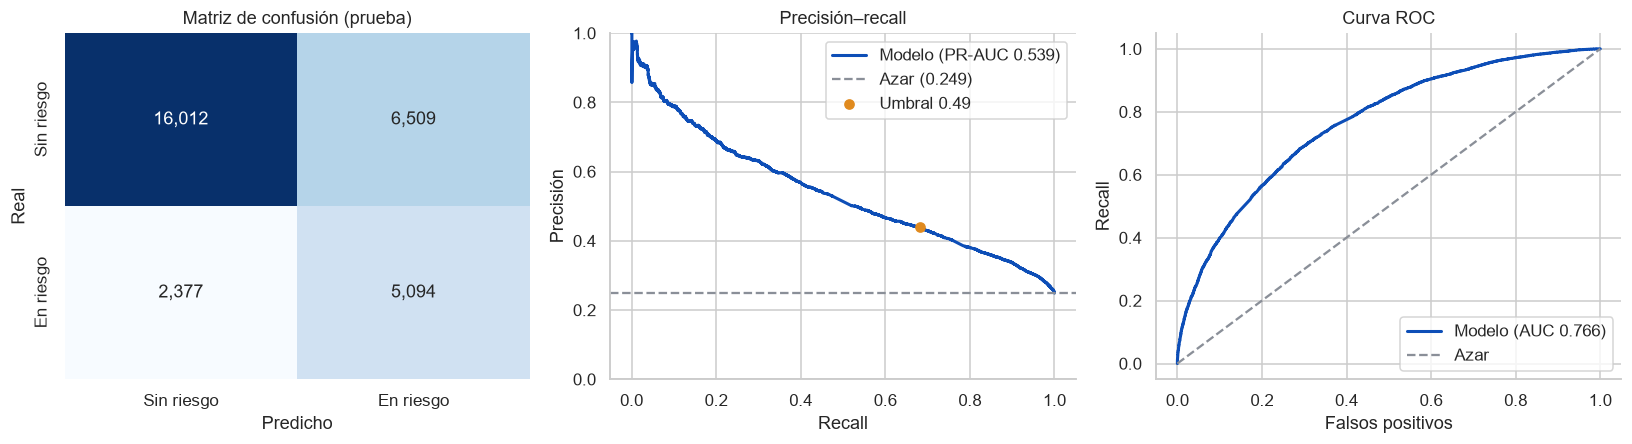

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

# matriz de confusion (filas = real, columnas = predicho)
cm = confusion_matrix(y, pred)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Sin riesgo", "En riesgo"], yticklabels=["Sin riesgo", "En riesgo"])
ax[0].set(title="Matriz de confusión (prueba)", xlabel="Predicho", ylabel="Real")

# curva precision-recall
p_, r_, _ = precision_recall_curve(y, prob)
ax[1].plot(r_, p_, color=azul, lw=2, label=f"Modelo (PR-AUC {m['pr_auc']:.3f})")
ax[1].axhline(prev, color=gris, ls="--", label=f"Azar ({prev:.3f})")
ax[1].scatter([m["recall"]], [m["precision"]], color=naranja, zorder=5, label=f"Umbral {UMBRAL:.2f}")
ax[1].set(title="Precisión–recall", xlabel="Recall", ylabel="Precisión", ylim=(0, 1))
ax[1].legend(loc="upper right")

# ROC
fpr, tpr, _ = roc_curve(y, prob)
ax[2].plot(fpr, tpr, color=azul, lw=2, label=f"Modelo (AUC {m['roc_auc']:.3f})")
ax[2].plot([0, 1], [0, 1], color=gris, ls="--", label="Azar")
ax[2].set(title="Curva ROC", xlabel="Falsos positivos", ylabel="Recall")
ax[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

### 4.1 Entrenamiento frente a prueba
Para saber si el modelo aprendió patrones generales o solo memorizó los datos con los que se entrenó, se miden las mismas métricas en los dos conjuntos. Una brecha pequeña indica que generaliza. Una brecha grande indica sobreajuste.

Entrenamiento reúne los conjuntos de train y validation, que son los datos con los que se ajustó el modelo final. Prueba es el 20 % que el modelo no vio. En ambos casos se usa el mismo umbral de decisión, y el historial del colegio sale de otros pliegues para que la medida de entrenamiento no salga inflada.

,Entrenamiento,Prueba,Brecha
PR-AUC,0.537,0.539,-0.002
ROC-AUC,0.763,0.766,-0.003
Recall,0.674,0.682,-0.008
Precisión,0.436,0.439,-0.003
F1,0.529,0.534,-0.005


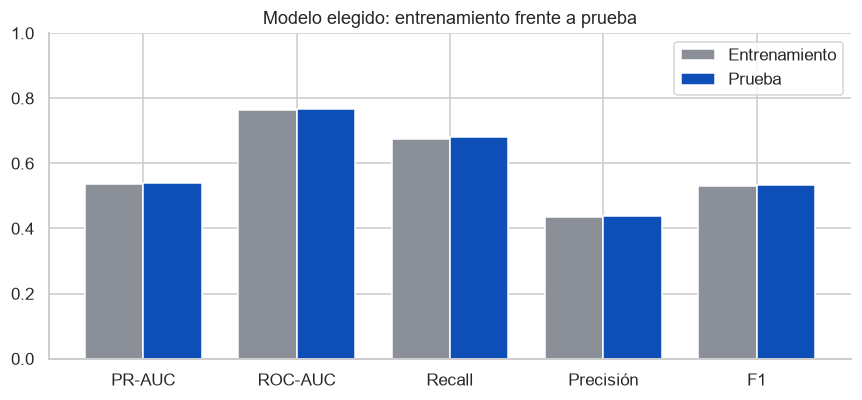

La brecha en PR-AUC entre entrenamiento y prueba es de **-0,002**, pequeña. El modelo generaliza y no memorizó los datos de entrenamiento.

In [7]:
claves = [("pr_auc", "PR-AUC"), ("roc_auc", "ROC-AUC"), ("recall", "Recall"), ("precision", "Precisión"), ("f1", "F1")]
if "metricas_entrenamiento" not in met:
    display(Markdown("Faltan las métricas de entrenamiento. Se generan al correr `python ml/entrenar_modelo.py`."))
else:
    tr, te = met["metricas_entrenamiento"], met["metricas_test"]
    tt = pd.DataFrame({"Entrenamiento": [tr[k] for k, _ in claves],
                       "Prueba": [te[k] for k, _ in claves]}, index=[n for _, n in claves])
    tt["Brecha"] = tt["Entrenamiento"] - tt["Prueba"]
    display(tt.round(3))

    fig, ax = plt.subplots(figsize=(8, 3.8))
    x = np.arange(len(tt)); w = 0.38
    ax.bar(x - w / 2, tt["Entrenamiento"], w, color=gris, label="Entrenamiento")
    ax.bar(x + w / 2, tt["Prueba"], w, color=azul, label="Prueba")
    ax.set_xticks(x); ax.set_xticklabels(tt.index); ax.set_ylim(0, 1)
    ax.set(title="Modelo elegido: entrenamiento frente a prueba"); ax.legend()
    plt.tight_layout(); plt.show()

    b = tt.loc["PR-AUC", "Brecha"]
    if b <= 0.03:
        lectura = "pequeña. El modelo generaliza y no memorizó los datos de entrenamiento."
    elif b <= 0.08:
        lectura = "moderada. Hay un leve sobreajuste, aceptable para un modelo lineal."
    else:
        lectura = "grande. Hay sobreajuste y conviene simplificar el modelo."
    display(Markdown(f"La brecha en PR-AUC entre entrenamiento y prueba es de **{num(b, 3)}**, {lectura}"))

La misma comparación sirvió para elegir entre los dos candidatos. Antes de entrenar el modelo final, cada uno se midió con los datos de train y con los de validation. El candidato que más se aleja entre uno y otro es el que más memoriza.

In [8]:
cand = pd.DataFrame(met["comparacion_validation"]).T
if "train_pr_auc" not in cand.columns:
    display(Markdown("Faltan las métricas de entrenamiento de los candidatos. Se generan al correr `python ml/entrenar_modelo.py`."))
else:
    cand["Brecha PR-AUC"] = cand["train_pr_auc"] - cand["validation_pr_auc"]
    vista = cand[["train_pr_auc", "validation_pr_auc", "Brecha PR-AUC"]].round(4)
    vista.columns = ["PR-AUC entrenamiento", "PR-AUC validación", "Brecha"]
    vista.index = [i.replace("_", " ").capitalize() + (" ← elegido" if i == met["modelo"] else "") for i in vista.index]
    display(vista)
    otro = [k for k in cand.index if k != met["modelo"]]
    if otro:
        b_el, b_otro = cand.loc[met["modelo"], "Brecha PR-AUC"], cand.loc[otro[0], "Brecha PR-AUC"]
        if b_otro > b_el:
            display(Markdown(f"El candidato descartado tiene una brecha de **{num(b_otro, 3)}**, mayor que la del elegido, **{num(b_el, 3)}**. "
                             "Además de rendir menos en validation, memoriza más, y eso respalda la decisión."))
        else:
            display(Markdown(f"La brecha del elegido es de **{num(b_el, 3)}** y la del otro candidato es de **{num(b_otro, 3)}**. "
                             "El elegido se mantuvo por su mayor PR-AUC en validation."))

,PR-AUC entrenamiento,PR-AUC validación,Brecha
Regresion logistica ← elegido,0.5343,0.5276,0.0067
Random forest,0.5318,0.5076,0.0242


El candidato descartado tiene una brecha de **0,024**, mayor que la del elegido, **0,007**. Además de rendir menos en validation, memoriza más, y eso respalda la decisión.

## 5. ¿Cómo leer la probabilidad?
El modelo se entrenó con las clases **balanceadas** `class_weight="balanced"` para no ignorar la minoría en riesgo. Eso hace que las probabilidades salgan **más altas que la
frecuencia real**: son un **puntaje de riesgo para ordenar**, no una probabilidad literal. Por eso el umbral de decisión no es 0,5 sino el que maximiza F1 en validación,
y el **umbral de alerta del dashboard no debe fijarse a ojo*: la tabla de abajo muestra qué se gana y qué se pierde con cada corte.

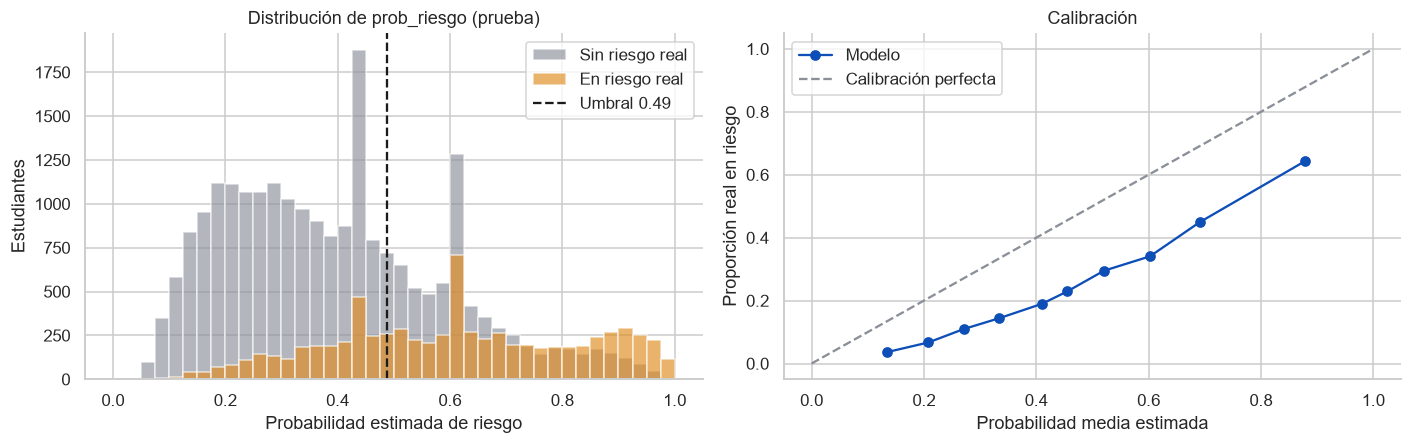

Probabilidad media estimada: **0,449**; proporción real en riesgo: **0,249**.

,% de estudiantes marcados,Precisión,Recall
Corte,,,
0.30,70.2,32.5,91.5
0.40,55.5,37.0,82.4
0.49,38.5,43.9,67.8
0.50,37.3,44.4,66.5
0.60,26.7,49.8,53.4
0.70,14.0,60.1,33.7


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.linspace(0, 1, 41)
ax[0].hist(prob[y == 0], bins=bins, alpha=.65, color=gris, label="Sin riesgo real")
ax[0].hist(prob[y == 1], bins=bins, alpha=.65, color=naranja, label="En riesgo real")
ax[0].axvline(UMBRAL, color="k", ls="--", label=f"Umbral {UMBRAL:.2f}")
ax[0].set(title="Distribución de prob_riesgo (prueba)", xlabel="Probabilidad estimada de riesgo", ylabel="Estudiantes")
ax[0].legend()

frac_pos, media_pred = calibration_curve(y, prob, n_bins=10, strategy="quantile")
ax[1].plot(media_pred, frac_pos, "o-", color=azul, label="Modelo")
ax[1].plot([0, 1], [0, 1], color=gris, ls="--", label="Calibración perfecta")
ax[1].set(title="Calibración", xlabel="Probabilidad media estimada", ylabel="Proporción real en riesgo")
ax[1].legend()
plt.tight_layout(); plt.show()

display(Markdown(f"Probabilidad media estimada: **{num(prob.mean(), 3)}**; proporción real en riesgo: **{num(prev, 3)}**."))

cortes = sorted(set([0.3, 0.4, round(UMBRAL, 2), 0.5, 0.6, 0.7]))
filas = []
for c in cortes:
    marca = prob >= c
    filas.append({"Corte": c, "% de estudiantes marcados": 100 * marca.mean(),
                  "Precisión": 100 * y[marca].mean() if marca.any() else np.nan,
                  "Recall": 100 * (marca & (y == 1)).sum() / (y == 1).sum()})
pd.DataFrame(filas).set_index("Corte").round(1)

## 6. Qué pesa más en las predicciones
**Importancia por permutación** sobre el conjunto de prueba: cuánto baja la PR-AUC si se «desordena» una variable. Mide asociación predictiva, no causas.

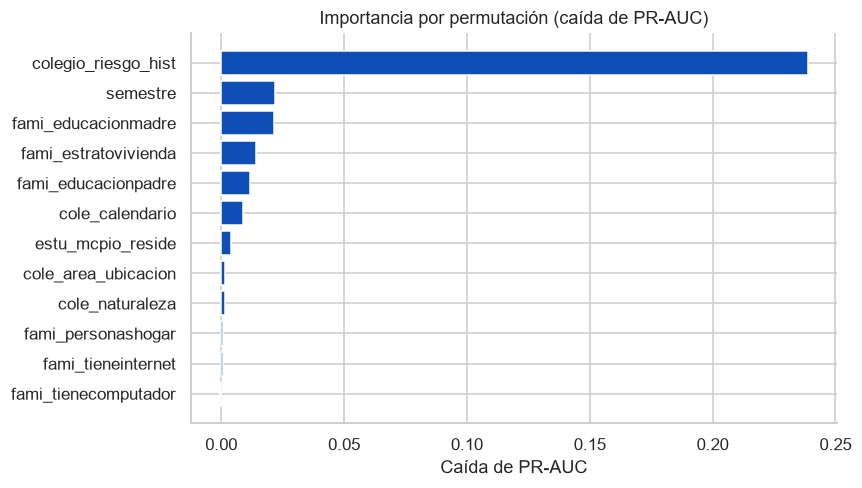

**Lectura.** La variable más importante es `colegio_riesgo_hist` (caída de 0,239), seguida de `semestre` (0,022). El historial del colegio pesa más que cualquier característica individual de la familia: **dónde estudia** el estudiante dice más que su perfil. Casi no aportan: `fami_personashogar`, `fami_tieneinternet`, `fami_tienecomputador`; podrían retirarse sin perder capacidad.

In [10]:
imp = pd.Series(met["importancia_permutacion_pr_auc"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(imp.index, imp.values, color=[azul if v > 0 else gris for v in imp.values])
ax.set(title="Importancia por permutación (caída de PR-AUC)", xlabel="Caída de PR-AUC")
plt.tight_layout(); plt.show()

top = imp.sort_values(ascending=False)
texto = (f"**Lectura.** La variable más importante es `{top.index[0]}` (caída de {num(top.iloc[0], 3)}), seguida de `{top.index[1]}` ({num(top.iloc[1], 3)}). ")
if top.index[0] == COL_HIST:
    texto += ("El historial del colegio pesa más que cualquier característica individual de la familia: **dónde estudia** el estudiante dice más que su perfil. ")
sin_aporte = [v for v, x in top.items() if x <= 0.001]
if sin_aporte:
    texto += f"Casi no aportan: {', '.join('`'+v+'`' for v in sin_aporte)}; podrían retirarse sin perder capacidad."
display(Markdown(texto))

## 7. ¿Funciona igual para todos los grupos?
Comparación del riesgo **real** con el **predicho** por grupos, en el conjunto de prueba. Si el modelo está bien orientado, los grupos con más riesgo real deben ser los que tienen más riesgo predicho.

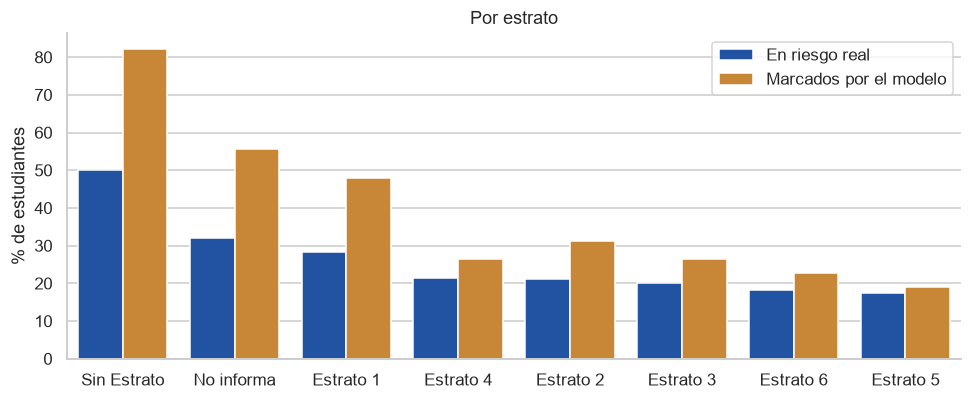

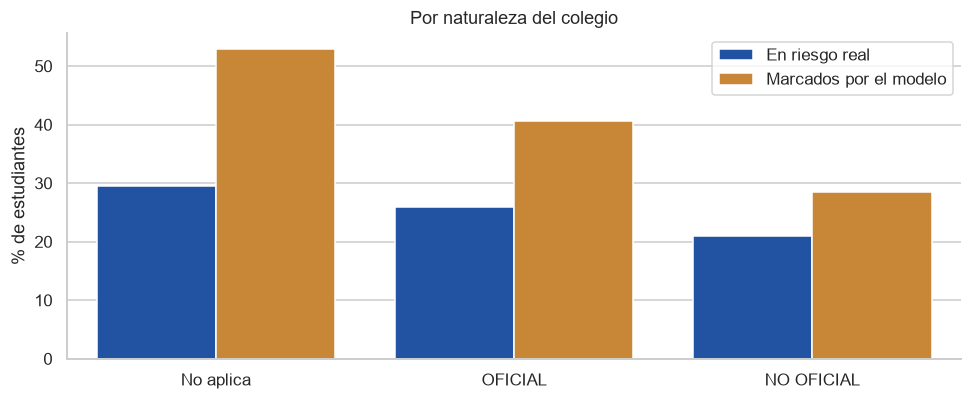

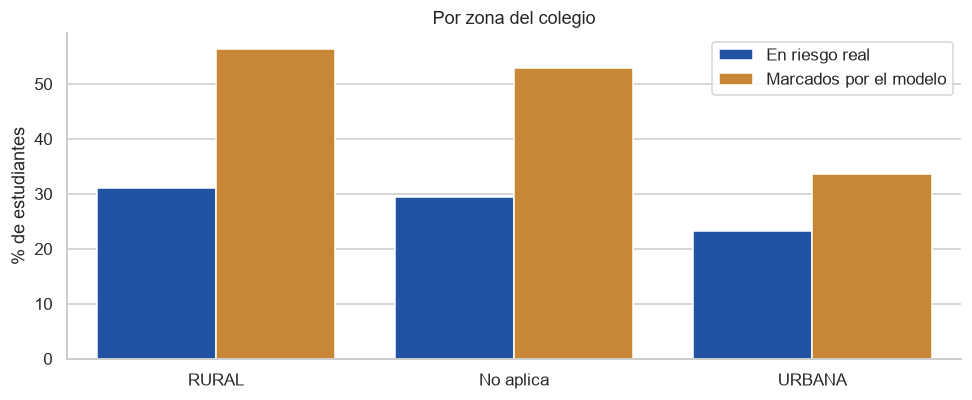

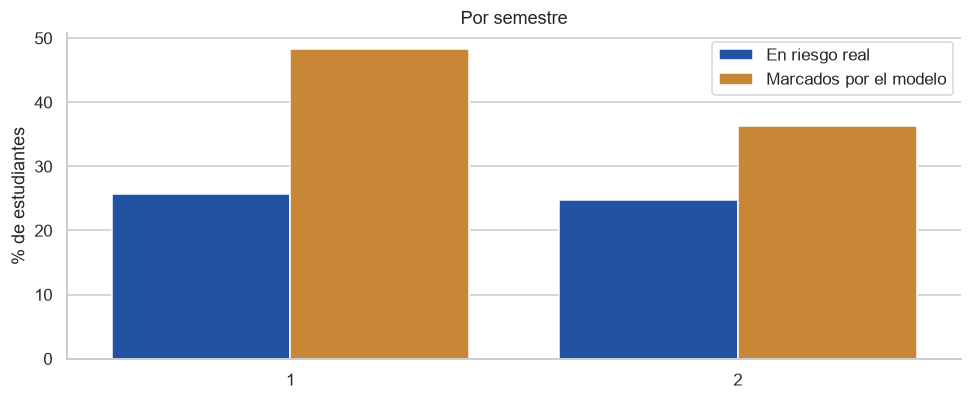

In [11]:
def por_grupo(col, min_n=100, top=None):
    g = (test.groupby(col).agg(estudiantes=("riesgo", "size"), real=("riesgo", "mean"),
                               predicho=("prob", "mean"), marcados=("pred", "mean")).reset_index())
    g = g[g["estudiantes"] >= min_n].sort_values("estudiantes", ascending=False)
    if top:
        g = g.head(top)
    return g

def grafico_grupo(col, titulo, min_n=100, top=None, horizontal=False):
    g = por_grupo(col, min_n, top).sort_values("real", ascending=False)
    fig, ax = plt.subplots(figsize=(9, max(3.2, 0.38 * len(g))) if horizontal else (9, 3.8))
    d = g.melt(id_vars=[col], value_vars=["real", "marcados"], var_name="medida", value_name="valor")
    d["medida"] = d["medida"].map({"real": "En riesgo real", "marcados": "Marcados por el modelo"})
    d["valor"] *= 100
    if horizontal:
        sns.barplot(data=d, y=col, x="valor", hue="medida", palette=[azul, naranja], ax=ax)
        ax.set(xlabel="% de estudiantes", ylabel="")
    else:
        sns.barplot(data=d, x=col, y="valor", hue="medida", palette=[azul, naranja], ax=ax)
        ax.set(ylabel="% de estudiantes", xlabel="")
    ax.set_title(titulo); ax.legend(title="")
    plt.tight_layout(); plt.show()
    return g

for col, tit in [("fami_estratovivienda", "Por estrato"), ("cole_naturaleza", "Por naturaleza del colegio"),
                 ("cole_area_ubicacion", "Por zona del colegio"), ("semestre", "Por semestre")]:
    grafico_grupo(col, tit, min_n=50)

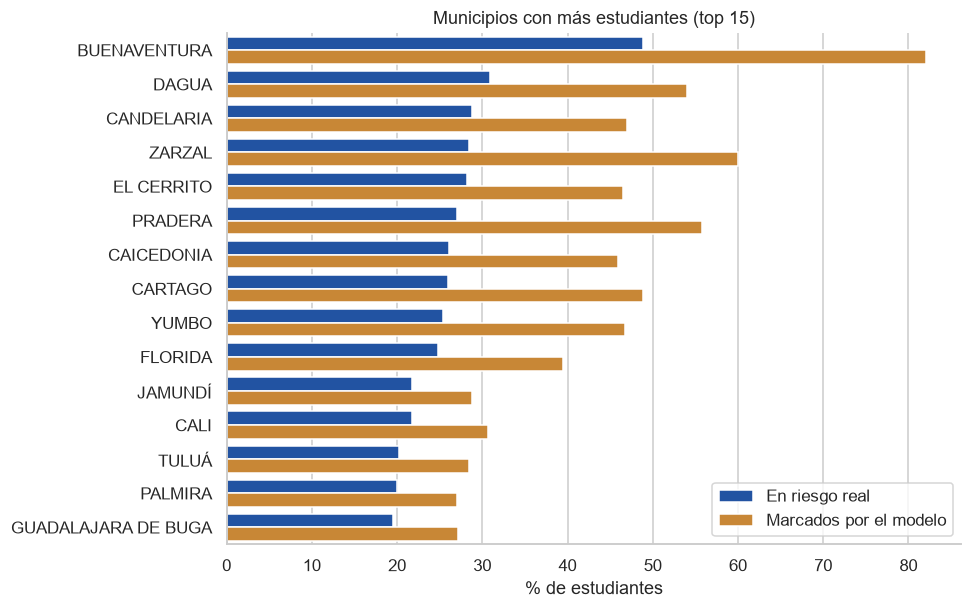

,Municipio,Estudiantes,% real,Prob. media (%),% marcados
8,CALI,14622,21.8,41.4,30.7
26,PALMIRA,2284,20.0,36.6,27.1
5,BUENAVENTURA,2219,48.8,70.2,82.1
35,TULUÁ,1549,20.3,37.9,28.4
21,JAMUNDÍ,1018,21.8,40.4,28.8
11,CARTAGO,942,26.0,48.0,48.8
20,GUADALAJARA DE BUGA,885,19.5,37.6,27.1
40,YUMBO,757,25.4,50.3,46.8
10,CANDELARIA,664,28.8,47.5,47.0
17,FLORIDA,451,24.8,48.6,39.5


In [12]:
g_mun = grafico_grupo("estu_mcpio_reside", "Municipios con más estudiantes (top 15)", min_n=150, top=15, horizontal=True)
tabla_mun = por_grupo("estu_mcpio_reside", min_n=150, top=15)
for c in ("real", "predicho", "marcados"):
    tabla_mun[c] = (100 * tabla_mun[c]).round(1)
tabla_mun.rename(columns={"estu_mcpio_reside": "Municipio", "estudiantes": "Estudiantes",
                          "real": "% real", "predicho": "Prob. media (%)", "marcados": "% marcados"})

## 8. Evaluación por colegio
En la práctica el dashboard sirve para **ver qué colegios y municipios necesitan más apoyo**, no para señalar estudiantes. Por eso se mide también qué tan bien el modelo
**ordena colegios**: se promedia, por colegio, el riesgo real y el predicho, se comparan y se mira cuántos de los colegios más riesgosos acierta.

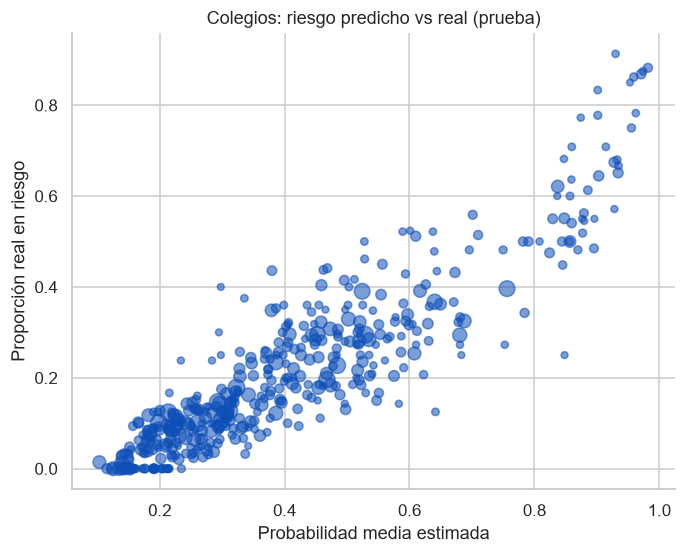

**442 colegios** con al menos 20 estudiantes en prueba. Correlación de Spearman entre riesgo real y predicho: **0,90**. De los **30 colegios más riesgosos** según los datos reales, el modelo acierta **80 %**. A nivel de colegio el modelo ordena mucho mejor que a nivel de estudiante, lo que respalda su uso para **priorizar apoyo por institución**.

In [13]:
MIN_N = 20
gc = (test.groupby(base.COL_COLEGIO).agg(estudiantes=("riesgo", "size"), real=("riesgo", "mean"), predicho=("prob", "mean"))
          .query("estudiantes >= @MIN_N"))
if len(gc) < 5:
    display(Markdown(f"Hay muy pocos colegios con al menos {MIN_N} estudiantes en prueba ({len(gc)}); no se puede medir a este nivel."))
else:
    rho = spearmanr(gc["real"], gc["predicho"])[0]
    k = max(3, min(30, len(gc) // 5))
    coincide = len(set(gc["real"].nlargest(k).index) & set(gc["predicho"].nlargest(k).index)) / k

    fig, ax = plt.subplots(figsize=(6.4, 5.2))
    ax.scatter(gc["predicho"], gc["real"], s=np.clip(gc["estudiantes"], 8, 120), alpha=.55, color=azul)
    ax.set(title="Colegios: riesgo predicho vs real (prueba)", xlabel="Probabilidad media estimada", ylabel="Proporción real en riesgo")
    plt.tight_layout(); plt.show()

    txt = (f"**{len(gc)} colegios** con al menos {MIN_N} estudiantes en prueba. Correlación de Spearman entre riesgo real y predicho: **{num(rho, 2)}**. "
           f"De los **{k} colegios más riesgosos** según los datos reales, el modelo acierta **{pct(coincide, 0)}**. ")
    if rho >= 0.6:
        txt += "A nivel de colegio el modelo ordena mucho mejor que a nivel de estudiante, lo que respalda su uso para **priorizar apoyo por institución**."
    else:
        txt += "A nivel de colegio la correspondencia es débil: conviene usar el modelo con cautela."
    display(Markdown(txt))

## 9. Prueba de robustez: entrenar con el pasado, predecir el futuro
La partición aleatoria es optimista: en la vida real el modelo se usa con estudiantes de **años posteriores**. Por eso se hizo una prueba temporal
(`ml/experimento_colegio.py`): se entrena con 2019 y 2020 y se evalúa en 2025. Se compara el modelo **sin** y **con** historial del colegio.

In [14]:
ruta_exp = MODELOS / "experimento_colegio.json"
if ruta_exp.exists():
    exp = json.loads(ruta_exp.read_text(encoding="utf-8"))
    nombres = {"A_particion_aleatoria": "A · Partición aleatoria", "B_temporal_2019_2020_a_2025": "B · Temporal (2019-2020 → 2025)"}
    filas = []
    for clave, bloque in exp.items():
        for tipo, etiqueta in (("base", "Sin historial del colegio"), ("con_historial", "Con historial del colegio")):
            r = bloque[tipo]
            filas.append({"Prueba": nombres.get(clave, clave), "Modelo": etiqueta,
                          "PR-AUC": r["pr_auc"], "ROC-AUC": r["roc_auc"],
                          "Spearman por colegio": r["por_colegio"].get("spearman"),
                          "Spearman por municipio": r["por_municipio"].get("spearman")})
    display(pd.DataFrame(filas).round(3).set_index(["Prueba", "Modelo"]))
    mejora = [exp[k]["con_historial"]["pr_auc"] - exp[k]["base"]["pr_auc"] for k in exp]
    txt = "**Lectura.** "
    if all(d > 0 for d in mejora):
        txt += ("En todas las pruebas el historial del colegio mejora la PR-AUC "
                f"(+{', +'.join(num(d, 3) for d in mejora)}), también cuando se predice un año posterior, "
                "así que la ganancia **no viene de ver los mismos datos**. ")
    else:
        txt += "El historial del colegio no mejora en todas las pruebas; revisar la tabla. "
    kt = [k for k in exp if k.startswith("B")]
    if kt:
        b = exp[kt[0]]
        txt += (f"La prueba temporal da PR-AUC {num(b['con_historial']['pr_auc'], 3)} (vs {num(exp[[k for k in exp if k.startswith('A')][0]]['con_historial']['pr_auc'], 3)} "
                "en la partición aleatoria): es el desempeño más realista a esperar. ")
        dm = b["con_historial"]["por_municipio"].get("spearman", np.nan) - b["base"]["por_municipio"].get("spearman", np.nan)
        txt += (f"A nivel de **municipio** el cambio en Spearman es de {num(dm, 2)}: la mejora está sobre todo en distinguir colegios, no municipios.")
    display(Markdown(txt))
else:
    display(Markdown("No se encontró `models/experimento_colegio.json`. Para generarlo: `python ml/experimento_colegio.py`."))

PR-AUC  ROC-AUC  \
Prueba                          Modelo                                       
A · Partición aleatoria         Sin historial del colegio   0.432    0.687   
                                Con historial del colegio   0.535    0.763   
B · Temporal (2019-2020 → 2025) Sin historial del colegio   0.383    0.671   
                                Con historial del colegio   0.474    0.739   

                                                           Spearman por colegio  \
Prueba                          Modelo                                            
A · Partición aleatoria         Sin historial del colegio                 0.740   
                                Con historial del colegio                 0.885   
B · Temporal (2019-2020 → 2025) Sin historial del colegio                 0.710   
                                Con historial del colegio                 0.831   

                                                           Spearman por municipio  
Prueba                          Modelo                                             
A · Partición aleatoria         Sin historial del colegio                   0.807  
                                Con historial del colegio                   0.808  
B · Temporal (2019-2020 → 2025) Sin historial del colegio                   0.742  
                                Con historial del colegio                   0.752

**Lectura.** En todas las pruebas el historial del colegio mejora la PR-AUC (+0,103, +0,091), también cuando se predice un año posterior, así que la ganancia **no viene de ver los mismos datos**. La prueba temporal da PR-AUC 0,474 (vs 0,535 en la partición aleatoria): es el desempeño más realista a esperar. A nivel de **municipio** el cambio en Spearman es de 0,01: la mejora está sobre todo en distinguir colegios, no municipios.

## 10. Limitaciones y uso responsable
- **Desempeño moderado.** Con una precisión cercana al 44 %, más de la mitad de los estudiantes marcados en riesgo no lo están. No es una herramienta para clasificar personas.
- **Asociación, no causa.** El estrato, la educación de los padres o el colegio se asocian con el puntaje, pero no lo causan por sí solos; no deben usarse para explicar el resultado de un estudiante.
- **Mezcla de factores.** El semestre y el tipo de colegio están relacionados entre sí, por lo que la importancia de cada uno no se puede separar del todo.
- **El historial del colegio puede estigmatizar.** Resume lo que pasó antes en una institución; un colegio que mejoró tardará en reflejarlo.
- **Colegios o municipios nuevos** reciben el promedio general, por lo que su predicción es menos informativa.
- **Datos limitados a 2019, 2020 y 2025.** Si cambian el examen o el contexto, hay que reentrenar y volver a medir.
- **Sobreestimación en municipios de alto riesgo.** En Buenaventura el modelo marca en riesgo al 82 % de los estudiantes cuando la frecuencia real es del 49 %. El orden entre municipios es correcto, pero los porcentajes marcados no deben leerse como frecuencias.
- **Probabilidad ≠ frecuencia real**: sirve para ordenar y priorizar.

**Valor que aporta:** convierte los datos del DW en una señal temprana por colegio y municipio, visible en tiempo real en el dashboard, para decidir dónde enfocar acompañamiento antes de que se publiquen los resultados.

## 11. Cómo regenerar este informe y el modelo
Se necesita Docker encendido con el Data Warehouse cargado.
```
docker compose up -d
python ml/entrenar_modelo.py
python ml/probar_consumer.py
python ml/experimento_colegio.py
jupyter nbconvert --to html --execute notebooks/info_modelo_ml.ipynb
```
- `entrenar_modelo.py` entrena el modelo y guarda los archivos de `models/`.
- `probar_consumer.py` verifica que el consumidor de Kafka puede usar el modelo guardado.
- `experimento_colegio.py` genera la prueba temporal de la sección 9.

Archivos en `models/`: `modelo_riesgo.joblib`, `metricas.json`, `ejemplo_mensaje.json`, `historial_colegios.json`, `ids_test.csv` y `experimento_colegio.json`.